# A Visual Story of the German Labor Market
## German Unemployment Trends (1991–2025)


---

### 1. Introduction
Since Germany reunited in 1990, the economic story has often been simple: *"The West is rich, and the East is trying to catch up."*

However, looking at data from the last 35 years, the reality is more complex. The unemployment gap between East and West has become much smaller (**Convergence**). Today, high unemployment is no longer just an "Eastern problem." Some cities in the West and the capital, Berlin, now face meaningful challenges (**Persistence**).

In this project, I use data visualization to challenge old stereotypes and show the true state of the German labor market.

### 2. Project Goal
My goal is to tell a data-driven story that answers two key questions:
1.  **The Catch-Up:** Has Eastern Germany successfully closed the gap with the West?
2.  **The New Hotspots:** Which regions are struggling today? (Is the "poor East" narrative still true?)


**Important Notes:**
* **2005 Reform:** In January 2005, a major policy change (Hartz IV) merged different types of social help. This caused a statistical "spike" in unemployment numbers that year.
* **2025 Data:** The dataset includes values for 2025. These are treated as the latest available statistics or finalized projections from the source file generated in early 2026.

---

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import plotly.express as px
from pathlib import Path

# Resolve paths relative to this notebook's folder.
try:
    BASE_DIR = Path(__vsc_ipynb_file__).parent  # set by VS Code
except NameError:
    BASE_DIR = Path.cwd()  # Jupyter Notebook/Lab start the kernel in the notebook's folder

df = pd.read_csv(BASE_DIR / 'german_unemployment_data.csv')

df.head()

,Year,State,Unemployment_Rate,Region
0,1991,Baden-Württemberg,3.7,West
1,1992,Baden-Württemberg,4.4,West
2,1993,Baden-Württemberg,6.3,West
3,1994,Baden-Württemberg,7.5,West
4,1995,Baden-Württemberg,7.4,West


##  Setting the Stage
Before plotting, we define a consistent visual style. We will use a specific color palette to represent our regions throughout the story:
* **Red:** East Germany (Historically higher unemployment)
* **Blue:** West Germany
* **Orange:** Berlin (Unique capital status)

In [2]:

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Define our storytelling colors
custom_palette = {'East': '#d62728', 'West': '#1f77b4', 'Berlin': '#ff7f0e'}



## Visual 1: The Convergence Story (1991–2025)
**Question:** Has the East caught up with the West?

This line chart aggregates the unemployment rate by Region. We look for the "gap" between the Red line (East) and Blue line (West).
* **Note:** The vertical line marks the 2005 "Hartz IV" reforms, a major turning point in German labor policy.

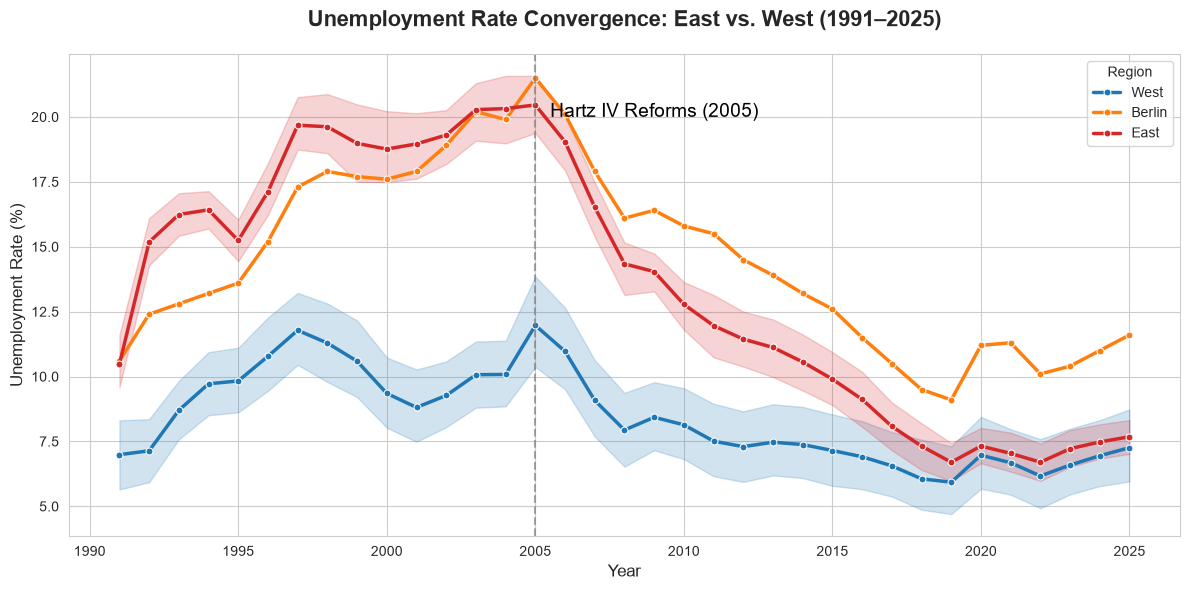

In [3]:
# Create the Line Plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df, 
    x='Year', 
    y='Unemployment_Rate', 
    hue='Region', 
    palette=custom_palette, 
    linewidth=2.5,
    marker='o',
    markersize=5
)


plt.title('Unemployment Rate Convergence: East vs. West (1991–2025)', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Unemployment Rate (%)', fontsize=12)
plt.xlabel('Year', fontsize=12)
plt.legend(title='Region')

# Mark the Hartz IV Reform
plt.axvline(x=2005, color='gray', linestyle='--', alpha=0.7)
plt.text(2005.5, 20, 'Hartz IV Reforms (2005)', color='black', fontsize=14)

plt.tight_layout()
plt.show()

**What this visual shows:**  
Average unemployment rates (%) for **East Germany, West Germany, and Berlin** from **1991 to 2025**. The vertical dashed line marks **2005 (Hartz IV reforms)**.

### Key results
- **East Germany starts much higher** than the West in the early 1990s, showing a clear post-reunification gap.
- Unemployment in the **East (and Berlin)** peaks in the early–mid 2000s, reaching around **~20%**, while the West stays clearly lower.
- After **2005**, unemployment **declines strongly in all regions**, but the drop is especially large in the East.
- Over time, the **East–West gap becomes smaller**, meaning the East moves closer to the West (convergence).
- In recent years, unemployment levels are **much closer than before**, but the East still tends to remain **slightly above** the West, while **Berlin stays relatively high**.

### Result
The trend supports the “catch-up” story: **Eastern Germany reduced the unemployment gap significantly**, especially after the mid-2000s.  
However, **full convergence is not complete**, and Berlin remains a persistent high-unemployment area compared to the West.



## Visual 2: Unemployment Rate by Federal State (Germany, 2025)


In [4]:


GEOJSON_PATH = BASE_DIR / "4_niedrig.geo.json"
YEAR_TO_PLOT = 2025   

with open(GEOJSON_PATH, "r", encoding="utf-8") as f:
    geojson = json.load(f)


df_map = (
    df[df["Year"] == YEAR_TO_PLOT]
    .groupby(["State", "Region"], as_index=False)["Unemployment_Rate"]
    .mean()
)


states_geo = [feat["properties"]["name"] for feat in geojson["features"]]
map_df = pd.DataFrame({"State": states_geo}).merge(df_map, on="State", how="left")

missing_states = map_df.loc[map_df["Unemployment_Rate"].isna(), "State"].tolist()


fig = px.choropleth(
    map_df,
    geojson=geojson,
    locations="State",
    featureidkey="properties.name",
    color="Unemployment_Rate",
    hover_name="State",
    hover_data={"Region": True, "Unemployment_Rate": ":.1f"},
    color_continuous_scale="blues"
)


fig.update_traces(
    hovertemplate=(
        "<b>%{hovertext}</b><br>"
        "Region: %{customdata[0]}<br>"
        "Unemployment: %{z:.1f}%<extra></extra>"
    )
)


fig.update_geos(
    fitbounds="locations",
    visible=False,
    projection_type="natural earth"
)

# Titles + legend (colorbar) title + size
title = f"<b>Unemployment Rate in Germany by Federal State ({YEAR_TO_PLOT})</b>"
subtitle = "Data source: Federal Employment Agency (processed)"
if missing_states:
    subtitle += f"<br><sup>Missing data for: {', '.join(missing_states)}</sup>"

fig.update_layout(
    title=dict(
        text=title + "<br><span style='font-size:14px'>" + subtitle + "</span>",
        x=0.5
    ),
    height=750,
    width=1300,
    margin=dict(l=5, r=5, t=90, b=5),
    coloraxis_colorbar=dict(title="Unemployment (%)", tickformat=".1f"),
)

fig.update_geos(
    fitbounds="locations",
    projection_scale=6.5,    
    center={"lat": 51.2, "lon": 10.4}  
)
fig.show()


*Static version of the map (the interactive map above is not displayed in GitHub's notebook preview):*

![Unemployment rate by federal state, 2025](images/unemployment_map_2025.png)

### What this map shows
This map displays the **unemployment rate (%)** for each German federal state in **2025**.  
Darker colors mean **higher unemployment**, lighter colors mean **lower unemployment**.

### Key results (easy interpretation)
- Unemployment is **not the same** across Germany — some states are clearly higher than others.
- Several **northern and eastern** areas appear darker, which suggests **higher unemployment** there.
- Many **southern states** are lighter, meaning they have **lower unemployment**.
- The map helps quickly see **where unemployment is concentrated** and which regions look more stable.

###  Result
In 2025, unemployment in Germany shows clear **regional differences**.  
The map supports the idea that labor market conditions depend strongly on the federal state.



## Visual 3: Which states have the highest unemployment in 2025?
This ranking highlights the top and bottom states in the most recent year. It complements the map by making comparisons precise.


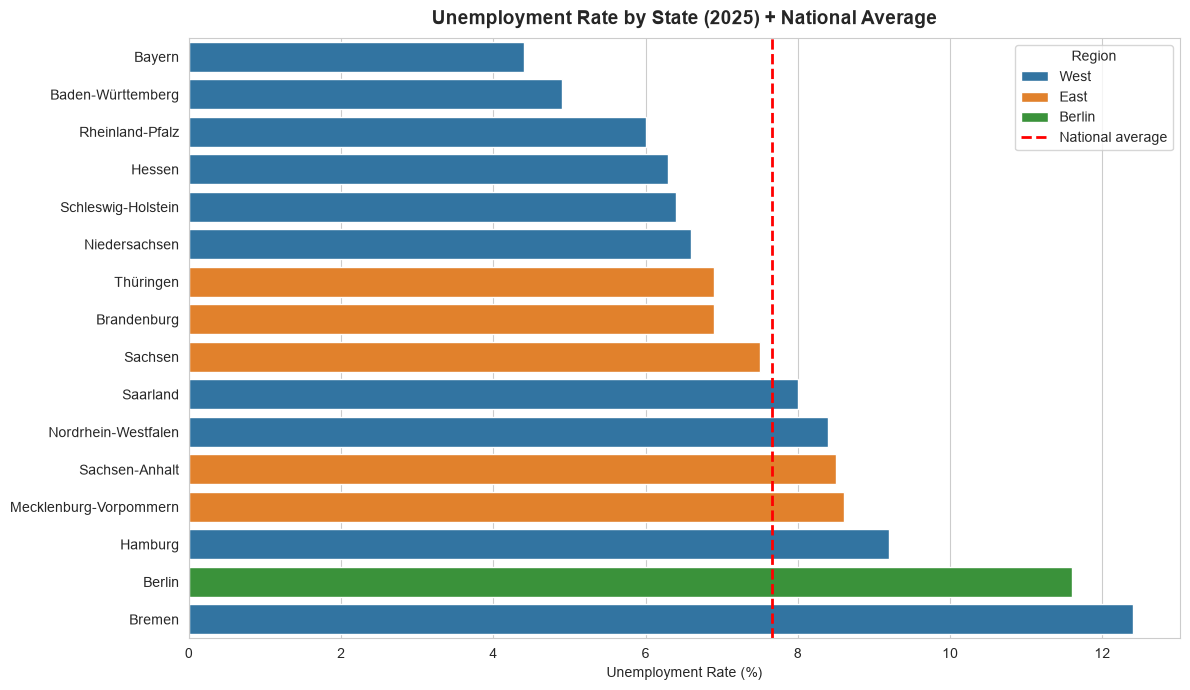

National average (2025): 7.66%


In [5]:


YEAR_TO_PLOT = 2025

rank_df = (
    df[df["Year"] == YEAR_TO_PLOT]
    .groupby(["State", "Region"], as_index=False)["Unemployment_Rate"]
    .mean()
    .sort_values("Unemployment_Rate", ascending=True)
)

national_avg = rank_df["Unemployment_Rate"].mean()

plt.figure(figsize=(12, 7))
sns.barplot(
    data=rank_df,
    y="State",
    x="Unemployment_Rate",
    hue="Region",
    dodge=False
)

plt.axvline(national_avg, linestyle="--", linewidth=2, color="red", label="National average")
plt.title(f"Unemployment Rate by State ({YEAR_TO_PLOT}) + National Average", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("")
plt.legend(title="Region")
plt.tight_layout()
plt.show()

print(f"National average ({YEAR_TO_PLOT}): {national_avg:.2f}%")




**What this visual shows:**  
A ranking of German federal states by **unemployment rate (%) in 2025**.  
The **red dashed line** is the **national average**, so it is easy to see which states are above or below the overall level.

### Key results
- States **left of the red line** are **below the national average** (better than average).
- States **right of the red line** are **above the national average** (worse than average).
- The lowest unemployment rates appear in **southern West states** such as **Bayern** and **Baden-Württemberg**.
- Several **Eastern states** (e.g., Sachsen-Anhalt, Mecklenburg-Vorpommern) are **above the national average**, showing that the East still faces challenges.
- However, the highest unemployment is **not only an Eastern issue**: **Bremen** (West) and **Berlin** stand out clearly as major hotspots.

### Result
In 2025, unemployment differences are strongly regional, but the “poor East only” stereotype is incomplete.  
Some of the most severe hotspots are **city-states and non-Eastern states**, while several West states perform well below the national average.


## Visual 4: Which states improved the most since 1991?

This chart compares unemployment rates in **1991 vs 2025** for each German federal state and shows the **percentage-point change** over time.
Negative values indicate an improvement (lower unemployment), while positive values indicate a deterioration.



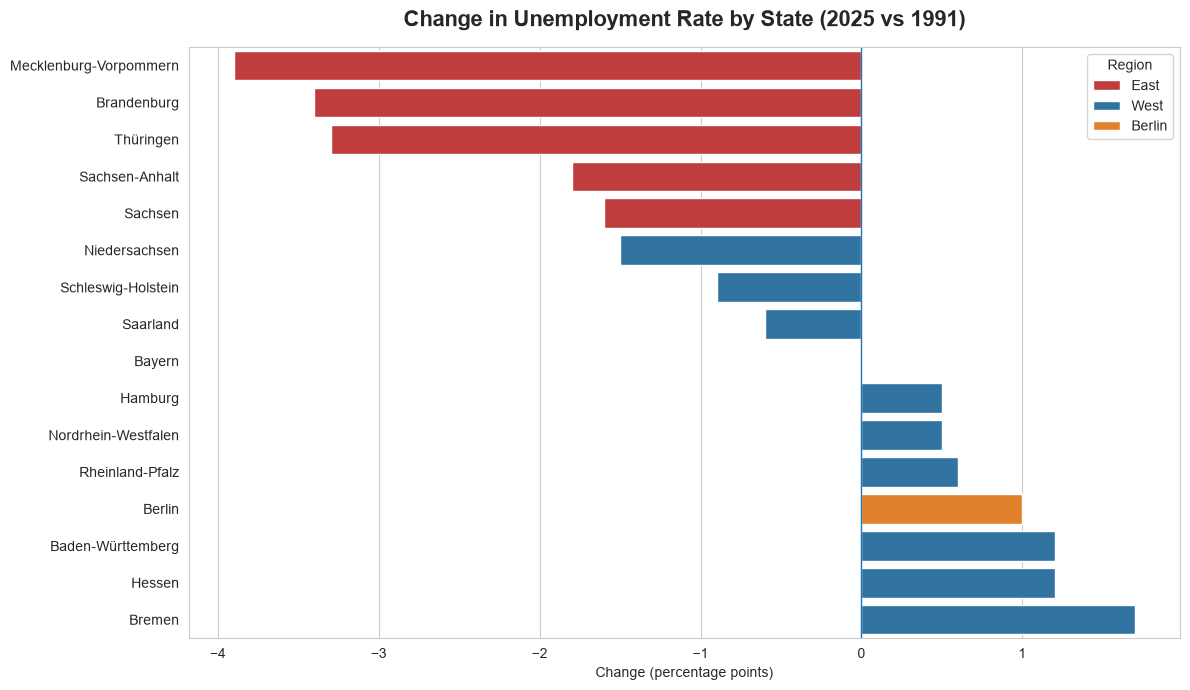

In [6]:


start_year, end_year = 1991, 2025

start_df = df[df["Year"] == start_year].groupby(["State","Region"], as_index=False)["Unemployment_Rate"].mean()
end_df   = df[df["Year"] == end_year].groupby(["State","Region"], as_index=False)["Unemployment_Rate"].mean()

change_df = start_df.merge(end_df, on=["State","Region"], suffixes=("_1991", "_2025"))
change_df["Change_pp"] = change_df["Unemployment_Rate_2025"] - change_df["Unemployment_Rate_1991"]
change_df = change_df.sort_values("Change_pp", ascending=True)

plt.figure(figsize=(12, 7))
sns.barplot(data=change_df, y="State", x="Change_pp", hue="Region", dodge=False, palette=custom_palette)
plt.axvline(0, linewidth=1)
plt.title("Change in Unemployment Rate by State (2025 vs 1991)", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Change (percentage points)")
plt.ylabel("")
plt.legend(title="Region")
plt.tight_layout()
plt.show()





**What this visual shows:**  
For each federal state, the bar shows the change in unemployment between **1991 and 2025**:  
**Change (pp) = Unemployment_2025 − Unemployment_1991**.  
The vertical **0 line** means **no change** (2025 equals 1991).

### Key results
- Bars **left of 0 (negative)** mean unemployment **decreased** since 1991 (improvement).
- Bars **right of 0 (positive)** mean unemployment **increased** since 1991 (worsening).
- Several **Eastern states** show the **largest decreases**, meaning they improved strongly over the long run (catch-up effect).
- At the same time, some places show **little improvement or even increases**, meaning progress has not been equal everywhere.
- City-states can stand out differently from territorial states, suggesting different labor-market structures.

### Result
This long-term comparison supports the “catch-up” story for many Eastern states (large decreases).  
However, the mixed results also show that Germany’s labor-market improvement was **not uniform**, and some regions still face persistent challenges.


# Visual 5: East–West Unemployment Gap Over Time (East − West)

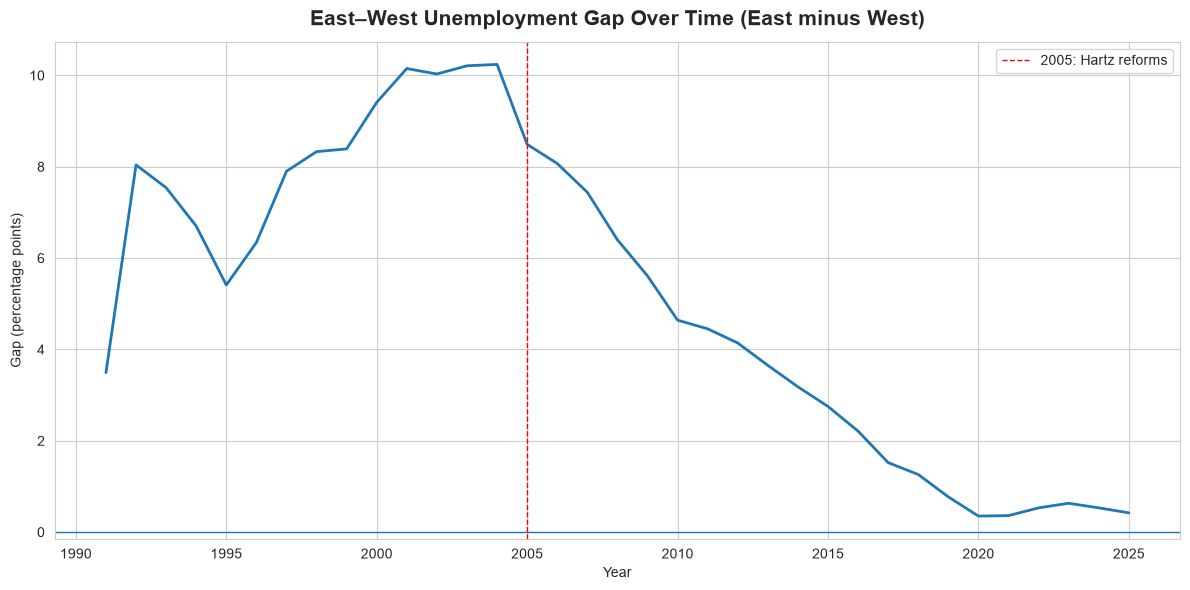

In [7]:


gap_df = (
    df[df["Region"].isin(["East", "West"])]
    .groupby(["Year", "Region"], as_index=False)["Unemployment_Rate"]
    .mean()
)

pivot = gap_df.pivot(index="Year", columns="Region", values="Unemployment_Rate").reset_index()
pivot["Gap_East_minus_West"] = pivot["East"] - pivot["West"]

plt.figure(figsize=(12, 6))
plt.plot(pivot["Year"], pivot["Gap_East_minus_West"], linewidth=2)
plt.axhline(0, linewidth=1)
plt.axvline(2005, linestyle="--", linewidth=1, color="red", label="2005: Hartz reforms")
plt.legend(loc="upper right")
plt.title("East–West Unemployment Gap Over Time (East minus West)", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("Year")
plt.ylabel("Gap (percentage points)")
plt.tight_layout()
plt.show()


**What this visual shows:**  
This line chart tracks the yearly difference in average unemployment between East and West Germany:  
**Gap = East average − West average**.  
The red dashed line marks **2005 (Hartz reforms)** as a reference point.

### Key results
- The gap stays **above 0** for almost the entire period, meaning unemployment is **consistently higher in the East** than in the West.
- The gap grows strongly in the 1990s and reaches its highest level in the early 2000s (around **~10 percentage points**).
- After 2005, the gap shows a **clear and long decline**, indicating strong convergence.
- By the 2020s, the gap becomes **very small** (close to **0–1 percentage point**), showing that the East moved much closer to the West.

### Result
This visual strongly supports the “catch-up” story: the East–West unemployment gap **shrunk dramatically** over time.  
However, the gap does not completely disappear, meaning small regional differences still remain.

## Conclusion

This project answered two questions:

1) **The Catch-Up:** Has Eastern Germany closed the unemployment gap with the West?  
2) **The New Hotspots:** Which regions struggle today, and is the “poor East” narrative still fully true?

### What we proved with the data (1991–2025)
- Our visuals show strong evidence that Eastern Germany was in a much worse situation after reunification. In the 1990s and early 2000s, unemployment in the East was far higher than in the West, and the East–West gap reached its maximum during that period. (Trend chart + gap chart)
- We also show clear evidence of improvement: the unemployment rate in the East declines strongly over time, and the gap between East and West becomes much smaller in the later years. In the 2020s, the gap is close to zero, which is strong proof of catch-up. (Trend chart + gap chart)
- In our time-series visuals, the period after 2005 is where we see the most clear and sustained decline in unemployment across all regions.
- This decline is especially important for the catch-up story: after 2005, unemployment in the East drops steadily and the gap with the West narrows more visibly.
- Our charts do not prove that the reforms were the only cause, but they strongly suggest that the post-2005 period is the main phase of improvement in the data.
### What we found about today (2025)
- Even after convergence, unemployment is still uneven across states in 2025. Some states are clearly below the national average, while others remain above it. (2025 map + ranking)
- The “poor East only” stereotype is not fully correct today. In the 2025 ranking, Berlin and Bremen stand out as important hotspots, showing that high unemployment is not limited to Eastern states. (2025 ranking / hotspot comparison)

### Final takeaway
Using year-by-year comparisons from 1991 to 2025, we demonstrated a clear story:  
**East Germany started with much higher unemployment, improved substantially over time, and reduced the gap with the West.**  
However, in 2025 the main unemployment problems are more **mixed and local**, not simply “East vs West.”
